# 06 · Canopy cover from classified photons

**Question:** can 30 m canopy cover be retrieved from classified ATL03 v007 photons once the canopy:ground reflectance ratio at
532 nm is accounted for, and how close is it to G-LiHT and UAV cover?

Method (Purslow et al. 2023, *Sci. Remote Sens.* 7:100086, §2.2 and §2.3.2; after Armston et al. 2013):
- Per segment, canopy and ground photon rates per shot, corrected for background noise: `Ev`, `Eg`.
- Within a region, `Ev` falls linearly as `Eg` rises: `Ev = Ev(100%) − (ρv/ρg)·Eg`. Fit by orthogonal least squares with **one
  slope shared by all tracks** and **one intercept per track** (absorbs atmospheric transmission), each track weighted by
  Pearson r² of Ev vs Eg; tracks need `Ev(100%)` and `Eg(0%)` > 0.25 photons per shot.
- `cover = 1 / (1 + (ρv/ρg) · Ng / Nv)`.

Differences from Purslow et al. (kept easy to switch later, see `lib/icesat2_photon_lib.py: fit_reflectance_ratio`):
30 m instead of 100 m segments; noise correction from the ATL03 background rate rather than the noise-window photon count;
reference photon labels from G-LiHT/UAV DTM + CHM rasters rather than a simulated ALS waveform.

The ratio is fitted twice: with **reference-labelled** photons (the Purslow set-up, no classification error) and with the
**reclassified** photons (what a production run can do). It is also fitted by land cover class to see how much it varies with
ground type, the non-linearity at 532 nm (bright lichen and snow, dark wet soil and burn scars).

### Terms used in this notebook (same in every notebook of this series)

**Photons and their classes**
| Term | What it is |
|---|---|
| **ATL03 v007 photons** | Every photon ICESat-2 recorded (signal and solar background), with height and position. Nothing is classified yet. "v007" is the NASA data release; every version below uses release 007. |
| **ATL08 v007 photon classes** | NASA's labels for those photons (noise / ground / canopy / top of canopy), from the ATL08 product. Our current training data are built from these. |
| **Reclassified photon classes** | Our own labels for the **same** photons, from `lib/icesat2_photon_lib.py: reclassify` with the thresholds of one config version (`config/atl03_reclass_v0.N.yaml`). |
| **Reference photon labels** | Labels from airborne lidar (G-LiHT) or UAV surface models: a photon at the reference ground is ground, between ground and the reference canopy top is canopy, far above or below is noise. Treated as the truth. |

**30 m segments: a name says whose photon classes, then who cut them into 30 m segments and computed the heights**
| | binned by SlideRule PhoREAL | binned by our code (`segment_metrics`) |
|---|---|---|
| **ATL08 v007 photon classes** | **ATL08 · PhoREAL (today)**: what our training files contain today | **ATL08 · our binning (control)**: same classes, our binning; any difference from "today" is binning, not classification |
| **reclassified photon classes** | (not made) | **reclassified v0.N**: the candidate product, config v0.N |

Comparing **today** with **reclassified v0.N** is the result that matters; the **control** shows how much of that difference
comes from binning alone. Earlier notebooks and LOG entries called these "current v7 30 m", "ATL08 classes → our 30 m (check)"
and "reclassified photons → our 30 m (new)".

`h_canopy` = 98th percentile of canopy-photon heights above the ground in a 30 m segment (as in ATL08).
**Reference height** of a segment = 98th percentile of the 1 m reference canopy height model (G-LiHT or UAV) inside the segment's footprint (30 m along track × 11 m).

In [1]:
import sys, os, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)

REPO = Path.cwd().resolve().parents[1]          # notebooks/atl03_reclass -> repo root
sys.path.insert(0, str(REPO / "lib"))
import icesat2_photon_lib as ipl, reference_lib as ref, validation_lib as val, plot_style as ps
ps.apply()   # shared figure style; vegetation-height colormap ps.HEIGHT_CMAP; ESRI Light Gray basemap ps.add_basemap

cfg = ipl.load_config(REPO / "config" / "atl03_reclass_v0.6.yaml")   # profile auto: 'maap' on MAAP ADE, else 'adapt'
WORK = Path(cfg["paths"]["work_dir"]); WORK.mkdir(parents=True, exist_ok=True)   # shared inputs: downloads, fetched photons, inventories
RUN = WORK / "runs" / f"v{cfg['version']}"; RUN.mkdir(parents=True, exist_ok=True)   # everything that depends on the config version
FIG = RUN / "figures"; FIG.mkdir(exist_ok=True)
print("profile:", cfg["profile"], "| config", cfg["version"], cfg["config_sha1"], "| work_dir:", WORK, "| run_dir:", RUN)
print(json.dumps(ipl.provenance(cfg), indent=1))

profile: adapt | config 0.6 40e8f82a4112 | work_dir: /explore/nobackup/people/pmontesa/atl03_reclass | run_dir: /explore/nobackup/people/pmontesa/atl03_reclass/runs/v0.6


{
 "repo": "circumpolar_boreal_trends",
 "git_commit": "0cecd4e",
 "git_dirty_lib_or_config": true,
 "config_version": "0.6",
 "config_sha1": "40e8f82a4112",
 "sliderule_client": "5.6.3",
 "processed_utc": "2026-10-18T12:22:16"
}


In [2]:
VAL = RUN / "validation"; OUT = RUN / "cover"; OUT.mkdir(exist_ok=True)
ph = gpd.read_parquet(RUN / "reclass" / "glihit_photons_reclassified.parquet")
sewph = pd.concat([gpd.read_parquet(f).assign(region="Seward") for f in sorted((RUN / "seward").glob("*_photons.parquet"))], ignore_index=True)
allph = pd.concat([ph, sewph], ignore_index=True)
allph = allph[~allph.get("disturbed", pd.Series(False, index=allph.index)).fillna(False).astype(bool)]
# reference-labelled photons as a classification: ground=1, canopy=2, everything else noise
allph["class_ref"] = allph.ref_label.map({"ground": 1, "canopy": 2}).fillna(0).astype(int)
inside = allph[allph.ref_label != "none"]
segs = {}
for scheme, col, rel in [("reference", "class_ref", "ref_relief"), ("new", "class_new", "relief_new")]:
    s = []
    for reg, g in inside.groupby("region"):
        x = ipl.segment_metrics(g, cfg, col, rel, scheme)
        if len(x): s.append(x.assign(region=reg))
    segs[scheme] = gpd.GeoDataFrame(pd.concat(s, ignore_index=True), crs=4326)
    print(scheme, len(segs[scheme]), "segments")

reference 4360 segments


new 3938 segments


## Canopy:ground reflectance ratio per region

**Input:** 30 m segments with background-corrected canopy and ground photon rates per shot (`Ev`, `Eg`), built twice: from the
**reference photon labels** (no classification error, as in Purslow et al.) and from the **reclassified photon classes**.

**What happens:** within a region, segments fall on a line from (Eg at 0 % cover, 0) to (0, Ev at 100 % cover). One slope
(−ρv/ρg) is fitted for all tracks, one intercept per track (`lib: fit_reflectance_ratio`).

**Output:** ρv/ρg per region and classification (`cover/reflectance_ratios.csv`).

In [3]:
fits, rows = {}, []
for scheme in ["reference", "new"]:
    for reg, g in segs[scheme].groupby("region"):
        f = ipl.fit_reflectance_ratio(g, cfg)
        fits[(scheme, reg)] = f
        tr = f["tracks"]
        rows.append({"scheme": scheme, "region": reg, "rho_v/rho_g": f["ratio"], "tracks_used": int(tr.used.sum()) if "used" in tr else 0,
                     "tracks_total": len(tr), "segments": len(g)})
ratios = pd.DataFrame(rows); ratios.to_csv(OUT / "reflectance_ratios.csv", index=False)
ratios.round(3)

,scheme,region,rho_v/rho_g,tracks_used,tracks_total,segments
0,reference,Interior,0.106,16,16,1950
1,reference,Kenai,0.316,23,23,1932
2,reference,Seward,0.455,11,11,478
3,new,Interior,0.112,12,12,1842
4,new,Kenai,0.318,25,25,1629
5,new,Seward,0.533,10,10,467


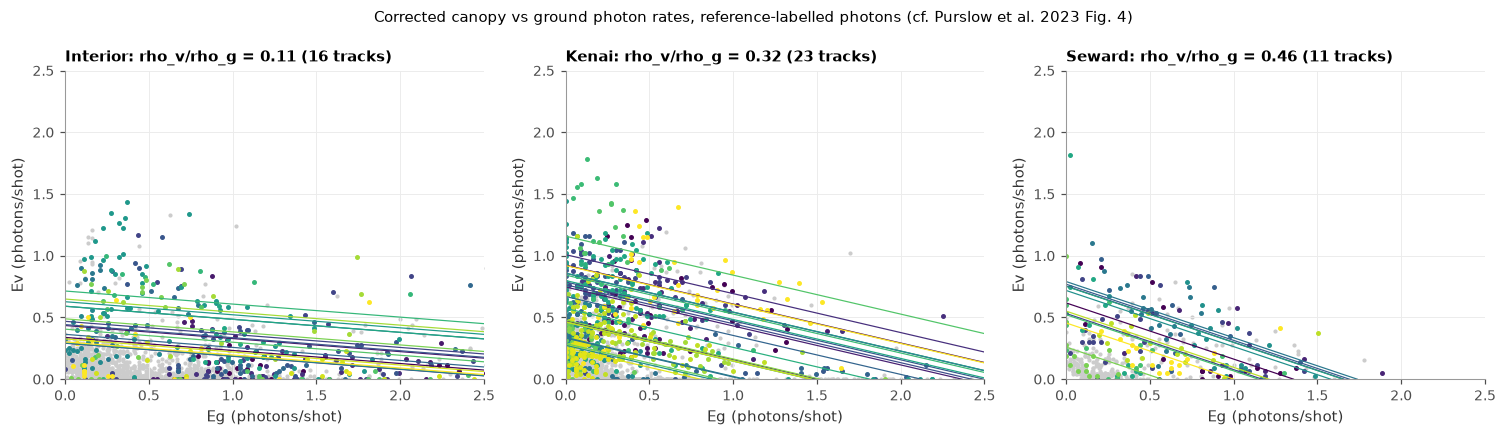

In [4]:
regs = sorted(segs["reference"].region.unique())
fig, axes = plt.subplots(1, len(regs), figsize=(4.6 * len(regs), 4), squeeze=False)
for ax, reg in zip(axes[0], regs):
    g = segs["reference"][segs["reference"].region == reg]
    f = fits.get(("reference", reg))
    if f is None or not np.isfinite(f["ratio"]): ax.set_title(f"{reg}: no fit"); continue
    tr = f["tracks"]; used = tr[tr.used] if "used" in tr else tr.iloc[0:0]
    cmap = plt.get_cmap("viridis", max(len(used), 1))
    for i, (_, t) in enumerate(used.iterrows()):
        gg = g[g.track_id == t.track]
        ax.scatter(gg.Eg, gg.Ev, s=5, color=cmap(i))
        xx = np.linspace(0, t.Eg0, 10); ax.plot(xx, t.Ev100 + f["slope"] * xx, color=cmap(i), lw=0.8)
    ax.scatter(g[~g.track_id.isin(used.track)].Eg, g[~g.track_id.isin(used.track)].Ev, s=3, c="0.8", zorder=0)
    ax.set_xlim(0, 2.5); ax.set_ylim(0, 2.5); ax.set_xlabel("Eg (photons/shot)"); ax.set_ylabel("Ev (photons/shot)")
    ax.set_title(f"{reg}: rho_v/rho_g = {f['ratio']:.2f} ({len(used)} tracks)", loc="left", fontsize=10)
fig.suptitle("Corrected canopy vs ground photon rates, reference-labelled photons (cf. Purslow et al. 2023 Fig. 4)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "06_rates_and_ratio.png", dpi=150)

## Does the ratio vary with ground type?

The same fit within each ATL08 land cover class (where there are enough tracks), using the reference-labelled photons. Large
differences between classes mean one ratio per region is not enough, which is the non-linearity at 532 nm (bright lichen and
snow, dark wet soil and burns).

In [5]:
rows = []
for reg, g in segs["reference"].groupby("region"):
    if "segment_landcover" not in g: continue
    for lc, gg in g.groupby("segment_landcover"):
        if gg.track_id.nunique() < 3 or len(gg) < 60: continue
        f = ipl.fit_reflectance_ratio(gg, cfg)
        rows.append({"region": reg, "landcover": lc, "segments": len(gg), "rho_v/rho_g": f["ratio"],
                     "tracks_used": int(f["tracks"].used.sum()) if "used" in f["tracks"] else 0})
pd.DataFrame(rows).round(3)

,region,landcover,segments,rho_v/rho_g,tracks_used
0,Interior,0,929,0.248,7
1,Interior,20,258,0.002,0
2,Interior,30,448,4.459,2
3,Interior,111,66,0.307,1
4,Interior,116,104,0.122,1
5,Interior,126,127,0.043,1
6,Kenai,0,1071,0.176,8
7,Kenai,30,183,1.585,3
8,Kenai,90,60,1.434,0
9,Kenai,111,90,5.547,1


## Cover vs airborne / UAV lidar cover

Reference cover: share of 1 m CHM pixels above 2 m (G-LiHT) or above 0.5 m (Seward UAV, shrub tundra) inside the segment
footprint. ICESat-2 cover from the reclassified photons with (a) ρv/ρg = 1 (no correction), (b) the ratio fitted from
reclassified photons, (c) the ratio fitted from reference-labelled photons.

bias_pts                                           \
version  ratio fitted (reclassified) ratio fitted (reference) rho_v/rho_g = 1   
region                                                                          
Interior                       40.63                    41.29           16.00   
Kenai                          24.59                    24.66           14.06   
Seward                         -3.64                    -2.20           -8.70   

                            rmse_pts                                           \
version  ratio fitted (reclassified) ratio fitted (reference) rho_v/rho_g = 1   
region                                                                          
Interior                       53.66                    54.28           28.73   
Kenai                          45.70                    45.76           36.84   
Seward                         31.38                    31.50           31.81   

                                  r2                                           
version  ratio fitted (reclassified) ratio fitted (reference) rho_v/rho_g = 1  
region                                                                         
Interior                        0.00                     0.00            0.00  
Kenai                           0.07                     0.07            0.06  
Seward                          0.12                     0.13            0.09

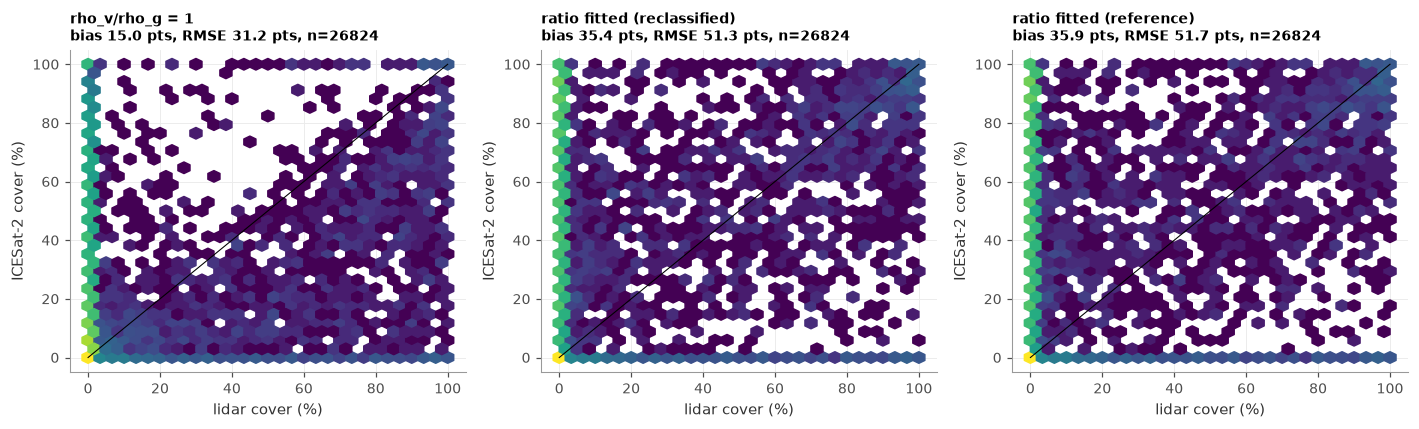

In [6]:
als = pd.concat([gpd.read_parquet(f) for f in sorted(VAL.glob("tile_*_segments_als.parquet"))], ignore_index=True)
sew = pd.concat([gpd.read_parquet(f) for f in sorted((RUN / "seward").glob("*_segments.parquet"))], ignore_index=True).assign(region="Seward")
ref_cover = pd.concat([als, sew], ignore_index=True)
ref_cover = ref_cover[ref_cover.als_n > 0]
ref_cover["ref_cover"] = np.where(ref_cover.region == "Seward", ref_cover["als_cover_0.5"], ref_cover["als_cover_2"])
c = ref_cover[["track_id", "seg", "region", "n_canopy", "n_ground", "ref_cover"]].copy()
r_new = ratios[ratios.scheme == "new"].set_index("region")["rho_v/rho_g"]
r_ref = ratios[ratios.scheme == "reference"].set_index("region")["rho_v/rho_g"]
c["cover_ratio1"] = ipl.canopy_cover(c.n_canopy, c.n_ground, 1.0)
c["cover_fit_new"] = ipl.canopy_cover(c.n_canopy, c.n_ground, c.region.map(r_new).fillna(cfg["cover"]["fallback_ratio"]).to_numpy())
c["cover_fit_ref"] = ipl.canopy_cover(c.n_canopy, c.n_ground, c.region.map(r_ref).fillna(cfg["cover"]["fallback_ratio"]).to_numpy())
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
rows = []
for ax, (col, ttl) in zip(axes, [("cover_ratio1", "rho_v/rho_g = 1"), ("cover_fit_new", "ratio fitted (reclassified)"), ("cover_fit_ref", "ratio fitted (reference)")]):
    d = c[[col, "ref_cover"]].dropna()
    ax.hexbin(d.ref_cover * 100, d[col] * 100, gridsize=30, extent=(0, 100, 0, 100), mincnt=1, bins="log", cmap="viridis")
    ax.plot([0, 100], [0, 100], c="k", lw=0.7)
    e = (d[col] - d.ref_cover) * 100
    ax.set_title(f"{ttl}\nbias {e.mean():.1f} pts, RMSE {np.sqrt((e**2).mean()):.1f} pts, n={len(d)}", loc="left", fontsize=9)
    ax.set_xlabel("lidar cover (%)"); ax.set_ylabel("ICESat-2 cover (%)")
    for reg, g in c.groupby("region"):
        dd = g[[col, "ref_cover"]].dropna(); ee = (dd[col] - dd.ref_cover) * 100
        rows.append({"version": ttl, "region": reg, "n": len(dd), "bias_pts": ee.mean(), "rmse_pts": np.sqrt((ee ** 2).mean()),
                     "r2": val.r_squared(dd.iloc[:, 0], dd.iloc[:, 1])})
fig.tight_layout(); fig.savefig(FIG / "06_cover_validation.png", dpi=150)
cv = pd.DataFrame(rows); cv.to_csv(OUT / "cover_validation.csv", index=False)
cv.pivot(index="region", columns="version", values=["bias_pts", "rmse_pts", "r2"]).round(2)

## Results (config v0.6, 18 October 2026): **on hold, not working**

- Fitted canopy:ground reflectance ratios ρv/ρg are implausibly low and region-dependent: Interior 0.11, Kenai 0.32, Seward
  0.53 with reclassified photons (reference photon labels give the same: 0.11, 0.32, 0.46), against 1.19 reported by Purslow et
  al. at Delta Junction; by land cover they range from 0.002 to 5.5.
- Cover with the fitted ratio is 25–41 points too high in forest (Interior, Kenai) with RMSE 46–54 points and r² ≤ 0.13; a ratio
  of 1 halves the bias but r² stays ≤ 0.09. The photon labels are not the problem (reference labels give the same result), so
  the rate model itself needs work before cover is used. Canopy cover stays on hold; heights are the deliverable.